In [1]:
%pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Create Student Dataset - 50 students
# Set seed to generate the same random data every time
np.random.seed(42)

data = {
    'Student_ID': range(1, 51),
    'Maths': np.random.randint(35, 100, 50),
    'Science': np.random.randint(30, 100, 50),
    'English': np.random.randint(40, 100, 50),
    'Attendance': np.random.randint(50, 100, 50),
    'Study_Hours': np.random.randint(1, 9, 50)
}

# Convert data into DataFrame
df = pd.DataFrame(data)

# Save dataset as CSV
df.to_csv("students.csv", index=False)

print("Dataset created successfully!")

df.head()

Dataset created successfully!


,Student_ID,Maths,Science,English,Attendance,Study_Hours
0,1,86,31,44,77,7
1,2,49,35,65,74,4
2,3,95,83,94,88,7
3,4,55,33,53,82,3
4,5,58,83,78,50,8


In [4]:
#Load and Explore Dataset
# Read CSV file
df = pd.read_csv("students.csv")

# Display first 5 records
display(df.head())

# Dataset information
df.info()

# Statistical summary
display(df.describe())

,Student_ID,Maths,Science,English,Attendance,Study_Hours
0,1,86,31,44,77,7
1,2,49,35,65,74,4
2,3,95,83,94,88,7
3,4,55,33,53,82,3
4,5,58,83,78,50,8


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Student_ID   50 non-null     int64
 1   Maths        50 non-null     int64
 2   Science      50 non-null     int64
 3   English      50 non-null     int64
 4   Attendance   50 non-null     int64
 5   Study_Hours  50 non-null     int64
dtypes: int64(6)
memory usage: 2.5 KB


,Student_ID,Maths,Science,English,Attendance,Study_Hours
count,50.00000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,25.50000,69.480000,61.120000,70.640000,74.940000,4.660000
std,14.57738,21.610882,20.591895,16.541549,15.560822,2.387125
min,1.00000,36.000000,30.000000,41.000000,50.000000,1.000000
25%,13.25000,49.750000,41.500000,55.250000,61.250000,3.000000
50%,25.50000,72.500000,63.000000,70.000000,77.000000,4.000000
75%,37.75000,88.500000,76.750000,83.000000,87.500000,7.000000
max,50.00000,98.000000,94.000000,99.000000,98.000000,8.000000


In [5]:
#Data Cleaning Using Pandas
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Fill missing marks with median
subjects = ['Maths', 'Science', 'English']

for subject in subjects:
    df[subject] = df[subject].fillna(
        df[subject].median()
    )

# Remove records missing attendance or study hours
df.dropna(subset=['Attendance', 'Study_Hours'], inplace=True)

# Calculate total marks
df['Total'] = df[subjects].sum(axis=1)

# Calculate percentage
df['Percentage'] = df['Total'] / 3

# Assign pass/fail status (40% minimum in each subject)
df['Result'] = np.where(
    (df[subjects] >= 40).all(axis=1),
    'Pass',
    'Fail'
)

print("Data Cleaning Completed!")

display(df.head())

Missing Values:
Student_ID     0
Maths          0
Science        0
English        0
Attendance     0
Study_Hours    0
dtype: int64
Data Cleaning Completed!


,Student_ID,Maths,Science,English,Attendance,Study_Hours,Total,Percentage,Result
0,1,86,31,44,77,7,161,53.666667,Fail
1,2,49,35,65,74,4,149,49.666667,Fail
2,3,95,83,94,88,7,272,90.666667,Pass
3,4,55,33,53,82,3,141,47.000000,Fail
4,5,58,83,78,50,8,219,73.000000,Pass


In [6]:
#Statistical Analysis Using NumPy
# Convert percentage column into NumPy array
marks = df['Percentage'].to_numpy()

print("STUDENT PERFORMANCE ANALYSIS")
print("----------------------------")

print("Average Percentage:", round(np.mean(marks), 2))

print("Highest Percentage:", round(np.max(marks), 2))

print("Lowest Percentage:", round(np.min(marks), 2))

print("Median Percentage:", round(np.median(marks), 2))

print("Standard Deviation:", round(np.std(marks), 2))

print("Total Students:", len(df))

print("Passed Students:", np.sum(df['Result'] == 'Pass'))

print("Failed Students:", np.sum(df['Result'] == 'Fail'))

STUDENT PERFORMANCE ANALYSIS
----------------------------
Average Percentage: 67.08
Highest Percentage: 91.67
Lowest Percentage: 38.33
Median Percentage: 67.5
Standard Deviation: 11.6
Total Students: 50
Passed Students: 34
Failed Students: 16


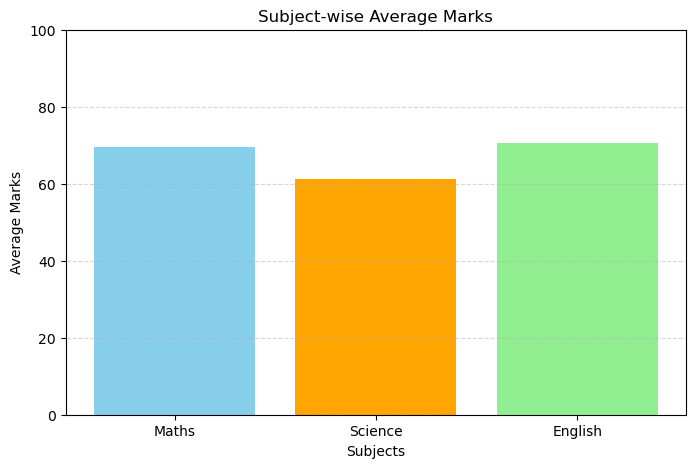

In [7]:
#Subject-wise Average Marks
# Calculate average marks
average_marks = df[subjects].mean()

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    average_marks.index,
    average_marks.values,
    color=['skyblue', 'orange', 'lightgreen']
)

plt.title("Subject-wise Average Marks")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.ylim(0, 100)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

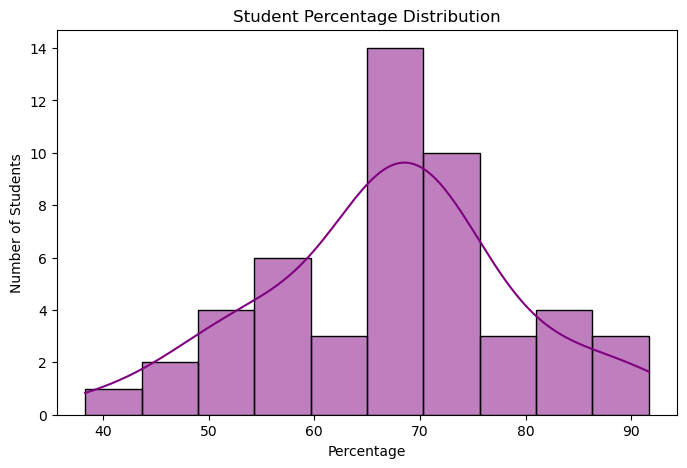

In [8]:
#Percentage Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Percentage'],
    bins=10,
    kde=True,
    color='purple'
)

plt.title("Student Percentage Distribution")
plt.xlabel("Percentage")
plt.ylabel("Number of Students")

plt.show()

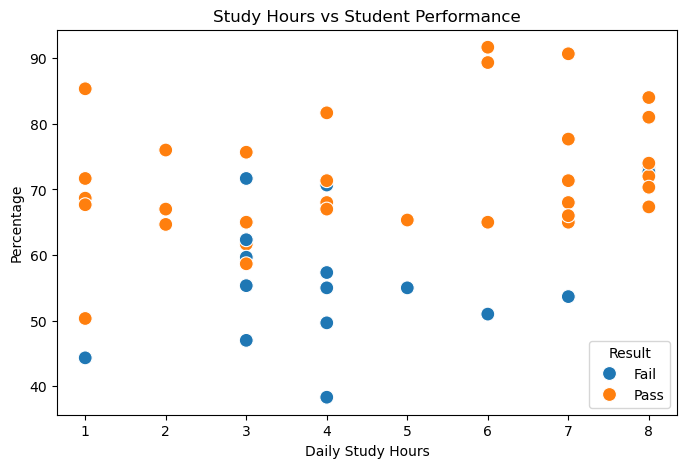

In [9]:
#Study Hours vs Percentage
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Study_Hours',
    y='Percentage',
    hue='Result',
    s=100
)

plt.title("Study Hours vs Student Performance")
plt.xlabel("Daily Study Hours")
plt.ylabel("Percentage")

plt.show()

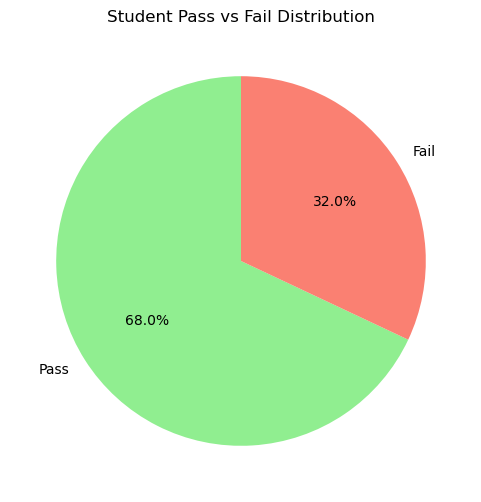

In [10]:
#Pass vs Fail
# Count pass and fail students
result_count = df['Result'].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    result_count.values,
    labels=result_count.index,
    autopct='%1.1f%%',
    colors=['lightgreen', 'salmon'],
    startangle=90
)

plt.title("Student Pass vs Fail Distribution")

plt.show()

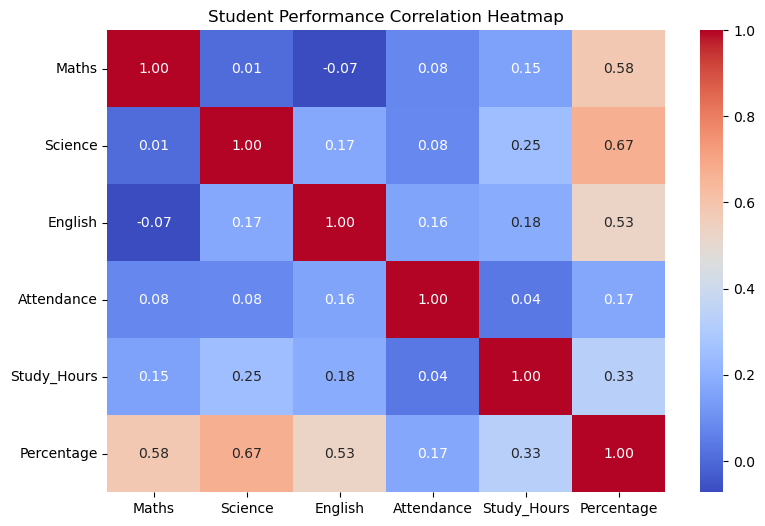

In [11]:
#Correlation Heatmap
# Select numerical columns
columns = [
    'Maths',
    'Science',
    'English',
    'Attendance',
    'Study_Hours',
    'Percentage'
]

# Calculate correlation
correlation = df[columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Student Performance Correlation Heatmap")

plt.show()

In [12]:
#Find Top 5 Students
# Sort students based on percentage
top_students = df.sort_values(
    by='Percentage',
    ascending=False
).head(5)

print("TOP 5 STUDENTS")

display(
    top_students[
        ['Student_ID', 'Total', 'Percentage', 'Result']
    ]
)

TOP 5 STUDENTS


,Student_ID,Total,Percentage,Result
13,14,275,91.666667,Pass
2,3,272,90.666667,Pass
23,24,268,89.333333,Pass
40,41,256,85.333333,Pass
42,43,252,84.000000,Pass


In [13]:
#Generate Final Analysis Report
print("=" * 45)
print("STUDENT PERFORMANCE ANALYSIS REPORT")
print("=" * 45)

print("Total Students:", len(df))

print("Average Percentage:", round(df['Percentage'].mean(), 2))

print("Highest Percentage:", round(df['Percentage'].max(), 2))

print("Lowest Percentage:", round(df['Percentage'].min(), 2))

print("Pass Count:", (df['Result'] == 'Pass').sum())

print("Fail Count:", (df['Result'] == 'Fail').sum())

print("Best Performing Subject:", df[subjects].mean().idxmax())

print("Lowest Performing Subject:", df[subjects].mean().idxmin())

print("=" * 45)

# Export final cleaned dataset
df.to_csv("cleaned_students.csv", index=False)

print("Cleaned dataset saved successfully!")

STUDENT PERFORMANCE ANALYSIS REPORT
Total Students: 50
Average Percentage: 67.08
Highest Percentage: 91.67
Lowest Percentage: 38.33
Pass Count: 34
Fail Count: 16
Best Performing Subject: English
Lowest Performing Subject: Science
Cleaned dataset saved successfully!
